# Исследование баланса целевой переменной Status
**Цель:** определить численность и доли классов исходов, оценить дисбаланс и сформулировать рекомендации по разбиению данных и оценке моделей.

Источник: Анализ проводится по исходному `train.csv`, до балансировки или иных преобразований. Данные соревнования синтетические: доли характеризуют эту выборку, а не клиническую популяцию.

## 1. Значения целевой переменной

| Класс | Интерпретация по описанию соревнования |
|---|---|
| C | Пациент жив на момент N_Days; наблюдение цензурировано |
| CL | Пациент жив на момент N_Days после трансплантации печени |
| D | Пациент умер к моменту N_Days |

Класс C не означает выздоровление или гарантированное дальнейшее выживание. Статусы относятся к сроку наблюдения N_Days и не задают единый горизонт прогноза, например один год. В этой части анализируется только Status; связи с признаками и обучение моделей находятся за её пределами.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.float_format', lambda x: f'{x:.2f}')
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11})
CLASSES = ['C', 'CL', 'D']
print('Библиотеки подключены.')

Библиотеки подключены.


## 2. Загрузка train.csv

In [2]:
DATA_PATH = Path('train.csv')
if not DATA_PATH.exists():
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError('Поместите train.csv рядом с ноутбуком.') from exc
    uploaded = files.upload()
    if 'train.csv' not in uploaded:
        raise FileNotFoundError('Нужно выбрать файл с именем train.csv.')

train = pd.read_csv(DATA_PATH)
print(f'Наблюдений: {len(train):,}; столбцов: {train.shape[1]}')
if 'Status' not in train.columns:
    raise ValueError('В файле нет Status. Проверьте, что загружен train.csv.')
print(train[['Status']].head().to_string(index=False))

Saving train.csv to train.csv
Наблюдений: 7,905; столбцов: 20
Status
     D
     C
     D
     C
     C


## 3. Проверка целевой переменной
Проверяем пропуски и допустимые значения. Неожиданные метки не исправляются автоматически: сначала нужно установить их происхождение. При проблемах расчёт останавливается, чтобы не получить неверные доли.

In [4]:
target = train['Status']
missing = int(target.isna().sum())
unexpected = target[target.notna() & ~target.isin(CLASSES)]
print('Тип данных:', target.dtype)
print('Уникальные значения:', target.unique().tolist())
print('Пропуски:', missing)
print('Неожиданные метки:', unexpected.unique().tolist())
if len(train) == 0:
    raise ValueError('Выборка пуста.')
if missing or len(unexpected):
    raise ValueError('Сначала разберите пропуски или неожиданные метки Status.')
if not set(CLASSES).issubset(set(target)):
    raise ValueError('Один из трёх ожидаемых классов отсутствует.')
print('Проверка пройдена: все статусы заполнены и соответствуют описанию.')

Тип данных: object
Уникальные значения: ['D', 'C', 'CL']
Пропуски: 0
Неожиданные метки: []
Проверка пройдена: все статусы заполнены и соответствуют описанию.


## 4. Численность и доли классов
Доля класса = число его наблюдений / общее число наблюдений × 100%. Порядок классов фиксирован для удобного сравнения.

In [5]:
counts = target.value_counts().reindex(CLASSES, fill_value=0)
shares = counts / len(train)
summary = pd.DataFrame({'Количество': counts, 'Доля, %': shares * 100})
summary.index.name = 'Status'
print(summary.to_string())
print(f'Проверка суммы: {counts.sum()} наблюдений, {shares.sum():.0%} выборки.')

        Количество  Доля, %
Status                     
C             4965    62.81
CL             275     3.48
D             2665    33.71
Проверка суммы: 7905 наблюдений, 100% выборки.


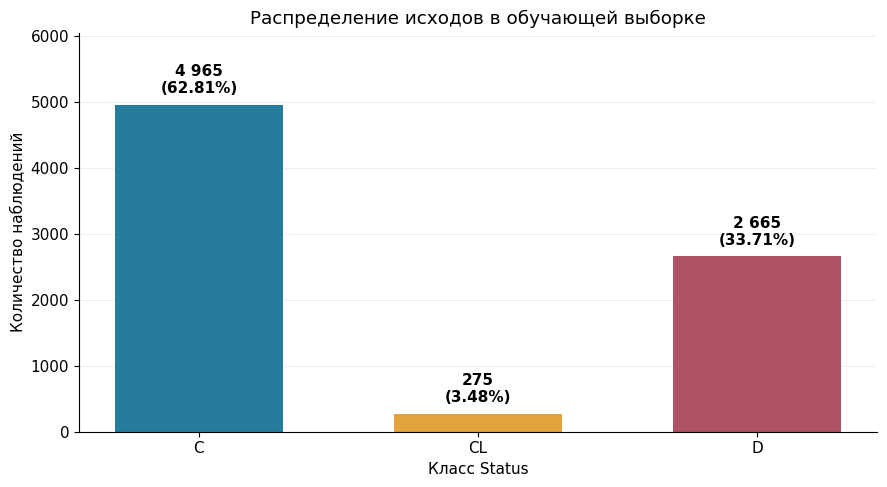

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(CLASSES, counts.values, color=['#257C9C', '#E3A23B', '#AF5265'], width=0.6)
for bar, count, share in zip(bars, counts.values, shares.values):
    label = f'{count:,}'.replace(',', ' ') + f'\n({share:.2%})'
    ax.text(bar.get_x() + bar.get_width()/2, count + counts.max()*0.025,
            label, ha='center', va='bottom', fontweight='bold')
ax.set(title='Распределение исходов в обучающей выборке',
       xlabel='Класс Status', ylabel='Количество наблюдений', ylim=(0, counts.max()*1.22))
ax.spines[['top', 'right']].set_visible(False)
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.18)
fig.tight_layout()
plt.show()

## 5. Оценка дисбаланса
Отношение численности самого частого класса к самому редкому: **IR = n_max / n_min**. Дополнительно учитываем абсолютное число наблюдений редкого класса. Единого универсального порога «сильного дисбаланса» для всех задач нет.

Accuracy постоянного прогноза наиболее частого класса показывает, почему общей доли правильных ответов недостаточно. Это описательный ориентир на всей выборке, а не проверенная на отложенных данных модель.

In [7]:
majority = counts.idxmax()
minority = counts.idxmin()
imbalance_ratio = counts.max() / counts.min()
print(f'Самый частый класс: {majority} — {counts.max()} ({shares[majority]:.2%}).')
print(f'Самый редкий класс: {minority} — {counts.min()} ({shares[minority]:.2%}).')
print(f'Отношение {majority}/{minority}: {imbalance_ratio:.2f}:1.')
print(f'Отношение D/CL: {counts["D"] / counts["CL"]:.2f}:1.')
print(f'Accuracy постоянного прогноза {majority}: {shares[majority]:.2%}.')

Самый частый класс: C — 4965 (62.81%).
Самый редкий класс: CL — 275 (3.48%).
Отношение C/CL: 18.05:1.
Отношение D/CL: 9.69:1.
Accuracy постоянного прогноза C: 62.81%.


## 6. Демонстрация стратифицированного разбиения 80/20
Фиксируем random_state=42. Стратификация сохраняет близкие доли классов, но не устраняет дисбаланс. Отложенная часть выделяется из train.csv; конкурсный test.csv не используется для локальной оценки качества.

In [8]:
from sklearn.model_selection import train_test_split

train_idx, valid_idx = train_test_split(
    train.index, test_size=0.20, random_state=42, stratify=target
)
train_counts = target.loc[train_idx].value_counts().reindex(CLASSES, fill_value=0)
valid_counts = target.loc[valid_idx].value_counts().reindex(CLASSES, fill_value=0)
split_summary = pd.DataFrame({
    'Всего': counts,
    'Обучение, n': train_counts,
    'Обучение, %': train_counts / len(train_idx) * 100,
    'Валидация, n': valid_counts,
    'Валидация, %': valid_counts / len(valid_idx) * 100,
})
print(split_summary.to_string())
print(f'Обучение: {len(train_idx)}; валидация: {len(valid_idx)}.')
print('Данные не изменены; разбиение показано для иллюстрации.')

        Всего  Обучение, n  Обучение, %  Валидация, n  Валидация, %
Status                                                             
C        4965         3972        62.81           993         62.81
CL        275          220         3.48            55          3.48
D        2665         2132        33.71           533         33.71
Обучение: 6324; валидация: 1581.
Данные не изменены; разбиение показано для иллюстрации.


## 7. Представленность классов при пятифолдовой кросс-валидации
Демонстрация на всей исходной обучающей выборке.

In [9]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold_counts = []
for fold, (_, fold_valid_idx) in enumerate(cv.split(train, target), start=1):
    current = target.iloc[fold_valid_idx].value_counts().reindex(CLASSES, fill_value=0)
    fold_counts.append({'Фолд': fold, **current.to_dict()})
print(pd.DataFrame(fold_counts).set_index('Фолд').to_string())

        C  CL    D
Фолд              
1     993  55  533
2     993  55  533
3     993  55  533
4     993  55  533
5     993  55  533


## 8. Вывод по рассчитанным данным

In [11]:
print(f'В обучающей выборке {len(train)} наблюдений. '
      f'Класс C: {counts["C"]} ({shares["C"]:.2%}); '
      f'CL: {counts["CL"]} ({shares["CL"]:.2%}); '
      f'D: {counts["D"]} ({shares["D"]:.2%}).')
print(f'Распределение неравномерно: класс {majority} встречается '
      f'в {imbalance_ratio:.2f} раза чаще класса {minority}. '
      'Дисбаланс следует учитывать при разбиении и оценке моделей.')
print(f'В демонстрационном разбиении в валидации остаётся '
      f'{valid_counts[minority]} наблюдений самого редкого класса. '
      'Небольшое число ошибок может заметно менять его метрики.')

В обучающей выборке 7905 наблюдений. Класс C: 4965 (62.81%); CL: 275 (3.48%); D: 2665 (33.71%).
Распределение неравномерно: класс C встречается в 18.05 раза чаще класса CL. Дисбаланс следует учитывать при разбиении и оценке моделей.
В демонстрационном разбиении в валидации остаётся 55 наблюдений самого редкого класса. Небольшое число ошибок может заметно менять его метрики.
